## Keras Tuner

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

In [17]:
X, y = make_moons(
    n_samples=2000, noise=0.25, random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(2,)))

    # Search number of hidden layers: 1 to 3
    for i in range(hp.Int("num_layers", 1, 3)):
        units = hp.Choice(
            f"units_{i}", values=[16, 32, 64, 128]
        )

        activation = hp.Choice(
            f"activation_{i}",
            values=["relu", "tanh"]
        )

        model.add(
            layers.Dense(units, activation=activation)
        )

    model.add(layers.Dense(1, activation="sigmoid"))

    # Search learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.0001, 0.001, 0.01]
    )

    optimizer_name = hp.Choice(
        "optimizer", values=["adam", "rmsprop"]
    )

    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [19]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="moon_classification",
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
activation_0 (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
learning_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'rmsprop'], 'ordered': False}


In [20]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

tuner.search(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Trial 10 Complete [00h 00m 05s]
val_accuracy: 0.934374988079071

Best val_accuracy So Far: 0.9468749761581421
Total elapsed time: 00h 02m 11s


In [21]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best number of layers:", best_hp.get("num_layers"))
print("Best learning rate:", best_hp.get("learning_rate"))
print("Best optimizer:", best_hp.get("optimizer"))

for i in range(best_hp.get("num_layers")):
    print(
        f"Layer {i + 1}:",
        best_hp.get(f"units_{i}"), "neurons,",
        best_hp.get(f"activation_{i}")
    )

Best number of layers: 2
Best learning rate: 0.001
Best optimizer: adam
Layer 1: 64 neurons, relu
Layer 2: 128 neurons, tanh


In [22]:
best_model = tuner.get_best_models(num_models=1)[0]

test_loss, test_accuracy = best_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

c:\Users\alili\100_days_Deep_Learning\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


Test Loss: 0.1673
Test Accuracy: 0.9250


In [23]:
tuner.results_summary(num_trials=5)

Results summary
Results in keras_tuner_results\moon_classification
Showing 5 best trials
Objective(name="val_accuracy", direction="max")

Trial 01 summary
Hyperparameters:
num_layers: 2
units_0: 64
activation_0: relu
learning_rate: 0.001
optimizer: adam
units_1: 128
activation_1: tanh
Score: 0.9468749761581421

Trial 03 summary
Hyperparameters:
num_layers: 2
units_0: 128
activation_0: relu
learning_rate: 0.001
optimizer: adam
units_1: 16
activation_1: relu
units_2: 64
activation_2: tanh
Score: 0.9437500238418579

Trial 09 summary
Hyperparameters:
num_layers: 3
units_0: 128
activation_0: relu
learning_rate: 0.01
optimizer: rmsprop
units_1: 64
activation_1: relu
units_2: 64
activation_2: relu
Score: 0.934374988079071

Trial 04 summary
Hyperparameters:
num_layers: 3
units_0: 32
activation_0: relu
learning_rate: 0.0001
optimizer: rmsprop
units_1: 32
activation_1: relu
units_2: 128
activation_2: tanh
Score: 0.859375

Trial 08 summary
Hyperparameters:
num_layers: 3
units_0: 16
activation_0: 

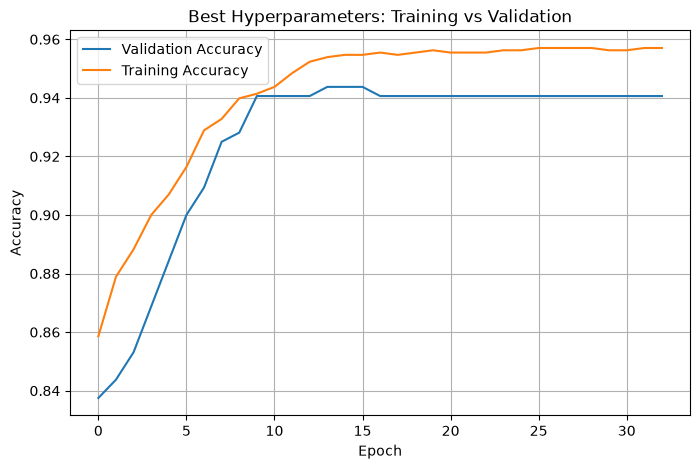

In [24]:
best_model = tuner.hypermodel.build(best_hp)

history = best_model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

plt.figure(figsize=(8, 5))
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Best Hyperparameters: Training vs Validation")
plt.legend()
plt.grid()
plt.show()